In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv('/content/dataAnalystJobsIndia_7th_July_2024.csv')

print(f'Total Rows and Columns :', df.shape)

print(df.info())

Total Rows and Columns : (1561, 16)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1561 entries, 0 to 1560
Data columns (total 16 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              1561 non-null   int64  
 1   job_title               1561 non-null   object 
 2   company                 1561 non-null   object 
 3   experience              1527 non-null   object 
 4   min exp                 1527 non-null   float64
 5   max exp                 1527 non-null   float64
 6   salary                  343 non-null    object 
 7   base salary             343 non-null    float64
 8   max salary              343 non-null    float64
 9   location                1528 non-null   object 
 10  jobListed(days ago)     1561 non-null   float64
 11  postedIn                1561 non-null   object 
 12  rating                  1124 non-null   float64
 13  reviews count           1124 non-null   float64
 14  deta

In [ ]:
df.head()

,job_title,company,experience,min exp,max exp,salary,base salary,max salary,location,jobListed(days ago),postedIn,rating,reviews count,details,salary data provide by
0,JP Morgan Chase - Client Data Analyst (4-8 yrs),JP Morgan Chase,4-8 Yrs,4.0,8.0,NaN,NaN,NaN,Hyderabad / Secunderabad,3.0,iimjobs,4.1,5300.0,"Banking, KYC, Banking Operations",NaN
1,Data Analyst - Bangalore,Schneider Electric,5-10 Yrs,5.0,10.0,₹ 8 - 16L/yr,800000.0,1600000.0,"Bangalore / Bengaluru, Bangalore Rural",4.0,Naukri,4.2,3500.0,"ERP, SAP, Data Analysis",Salary Listed by Company
2,Senior IT ATLAS Data Analyst and Integration S...,SAP Labs India Pvt. Ltd.,7-11 Yrs,7.0,11.0,NaN,NaN,NaN,Bangalore / Bengaluru,7.0,Naukri,4.3,1500.0,"data quality, Data analysis, quality management",NaN
3,Consultant Data Analyst,Pfizer,2-6 Yrs,2.0,6.0,NaN,NaN,NaN,Mumbai,3.0,Naukri,4.1,1700.0,"Power Bi, Commercial Operations, Data Management",NaN
4,Senior Data Analyst - Retail Liabilities,IDFC FIRST Bank,5-10 Yrs,5.0,10.0,NaN,NaN,NaN,Mumbai,5.0,Naukri,4.5,2300.0,"Test strategy, Analytical, Manager Technology",NaN


In [ ]:
# Let's Drop the unnecessary index artifact column if it exists
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1561 entries, 0 to 1560
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   job_title               1561 non-null   object 
 1   company                 1561 non-null   object 
 2   experience              1527 non-null   object 
 3   min exp                 1527 non-null   float64
 4   max exp                 1527 non-null   float64
 5   salary                  343 non-null    object 
 6   base salary             343 non-null    float64
 7   max salary              343 non-null    float64
 8   location                1528 non-null   object 
 9   jobListed(days ago)     1561 non-null   float64
 10  postedIn                1561 non-null   object 
 11  rating                  1124 non-null   float64
 12  reviews count           1124 non-null   float64
 13  details                 1528 non-null   object 
 14  salary data provide by  343 non-null    

# 1. Data Cleaning and Preprocessing
1.1 Handle Missing Values in the Dataset Appropriately




In [ ]:
# Let's Check the number of missing values in each column
df.isnull().sum()

,0
job_title,0
company,0
experience,34
min exp,34
max exp,34
salary,1218
base salary,1218
max salary,1218
location,33
jobListed(days ago),0


After examining the missing values, I decided not to remove the rows containing missing values.

The reason is that a missing value in one column does not mean that the entire job listing is invalid.

For example, a job listing may contain:

Job Title    → Data Analyst

Company      → ABC Company

Location     → Delhi

Salary       → Missing

Rating       → 4.2

This is still a valid job listing. Only the salary information is unavailable.

Therefore, I retained the missing values as NaN instead of replacing them with arbitrary values such as 0.

# 1.2 Normalize the salary Column

The assignment says:

Normalize the salary column to extract numerical values for base and max salary if not present.

First, I inspected the salary column.

Some examples are:

₹ 8 - 16L/yr

₹ 1.8 - 7L/yr (AmbitionBox estimate)

₹ 4.754 - 7L/yr (AmbitionBox estimate)

The dataset already contains two numerical columns:

base salary

max salary

Therefore, numerical salary values are already available.

Instead of unnecessarily recreating these columns, I used regular expressions to validate whether the existing numerical values agree with the original salary text.

In [ ]:
salary_pattern = r'₹\s*([\d.]+)\s*-\s*([\d.]+)L'

salary_extracted = df['salary'].str.extract(salary_pattern)

salary_extracted.columns = ['expected_base', 'expected_max']

salary_extracted = salary_extracted.astype(float) * 100000

salary_extracted.head()

,expected_base,expected_max
0,NaN,NaN
1,800000.0,1600000.0
2,NaN,NaN
3,NaN,NaN
4,NaN,NaN


# What does this do?

Suppose the salary is:

₹ 8 - 16L/yr

The regular expression extracts:

8

16

Because L represents lakh:

8 × 100000  = 800000

16 × 100000 = 1600000

So the expected values are:

expected_base = 800000

expected_max  = 1600000

# We can then compare these values with the existing columns.

In [ ]:
base_match = np.isclose(
    salary_extracted['expected_base'],
    df['base salary'],
    equal_nan=False
)

max_match = np.isclose(
    salary_extracted['expected_max'],
    df['max salary'],
    equal_nan=False
)


# Why did I use regex even though the columns already exist?

Because the salary column is the original textual source, while base salary and max salary are derived numerical fields.

There is a possibility of a data-entry error.

For example:

salary       = ₹ 8 - 16L/yr

base salary  = 8000       ❌

The regex validation would identify that the expected base salary is:

800000

rather than:

8000

Therefore, regex is useful here as a validation mechanism.

#Conclusion

The dataset already contains numerical base salary and max salary columns. Therefore, it was not necessary to recreate these columns. However, regular expressions were used to extract the expected numerical values from the original salary text and validate the existing salary columns. The values were found to be consistent, so no correction or replacement was required.

# 1.3 Standardize the experience Column

In [ ]:

# Standardize experience
# --------------------------------------------------

df['experience'] = np.where(
    df['min exp'].notna() & df['max exp'].notna(),
    df['min exp'].astype('Int64').astype(str) +
    '-' +
    df['max exp'].astype('Int64').astype(str) +
    ' Yrs',
    df['experience']
)

# Check result
print(df[['salary', 'base salary', 'max salary',
          'experience', 'min exp', 'max exp']].head(10))

         salary  base salary  max salary experience  min exp  max exp
0           NaN          NaN         NaN    4-8 Yrs      4.0      8.0
1  ₹ 8 - 16L/yr     800000.0   1600000.0   5-10 Yrs      5.0     10.0
2           NaN          NaN         NaN   7-11 Yrs      7.0     11.0
3           NaN          NaN         NaN    2-6 Yrs      2.0      6.0
4           NaN          NaN         NaN   5-10 Yrs      5.0     10.0
5           NaN          NaN         NaN    4-9 Yrs      4.0      9.0
6           NaN          NaN         NaN    5-9 Yrs      5.0      9.0
7           NaN          NaN         NaN    2-6 Yrs      2.0      6.0
8           NaN          NaN         NaN    6-8 Yrs      6.0      8.0
9           NaN          NaN         NaN   5-10 Yrs      5.0     10.0


# 2. Exploratory Data Analysis (EDA):
○ Perform EDA to find trends in job listings based on location,
company, and experience level.

○ Visualize the distribution of job ratings and reviews count.

# 1. Job listings based on Location

We can find which locations have the highest number of Data Analyst job listings.

location
Bangalore / Bengaluru                                          336
Mumbai                                                         165
Hyderabad / Secunderabad                                       129
Gurgaon / Gurugram                                             115
Pune                                                            90
Chennai                                                         81
Remote                                                          55
Noida                                                           42
New Delhi                                                       40
Chennai, Pune, New Delhi\n\t\t\t\t\t\t\t\t\t\t\t\t\t+4 more     31
Name: count, dtype: int64


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 9 (	) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


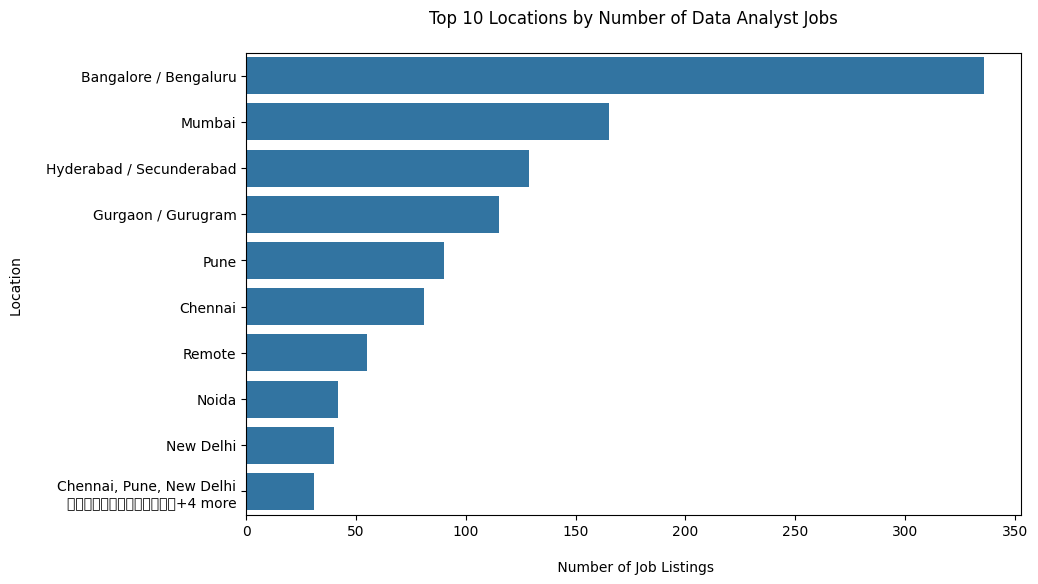

In [ ]:
location_counts = df["location"].value_counts().head(10)

print(location_counts)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=location_counts.values,
    y=location_counts.index
)

plt.title("Top 10 Locations by Number of Data Analyst Jobs\n")
plt.xlabel("\n Number of Job Listings")
plt.ylabel("Location \n")
plt.show()

# 2. Job listings based on Company

Now let's find which companies have the most Data Analyst job listings.

company
Diverse Lynx                             24
RIGHT STEP CONSULTING PRIVATE LIMITED    14
HuQuo Consulting Pvt. Ltd.               13
Coders Brain Pvt Ltd                     13
Essenware Private Limted                 11
IDFC FIRST Bank                          10
Huquo Consulting                         10
Fusion Plus Solutions Inc                10
D2N SOLUTIONS                             9
iXie Gaming                               9
Name: count, dtype: int64


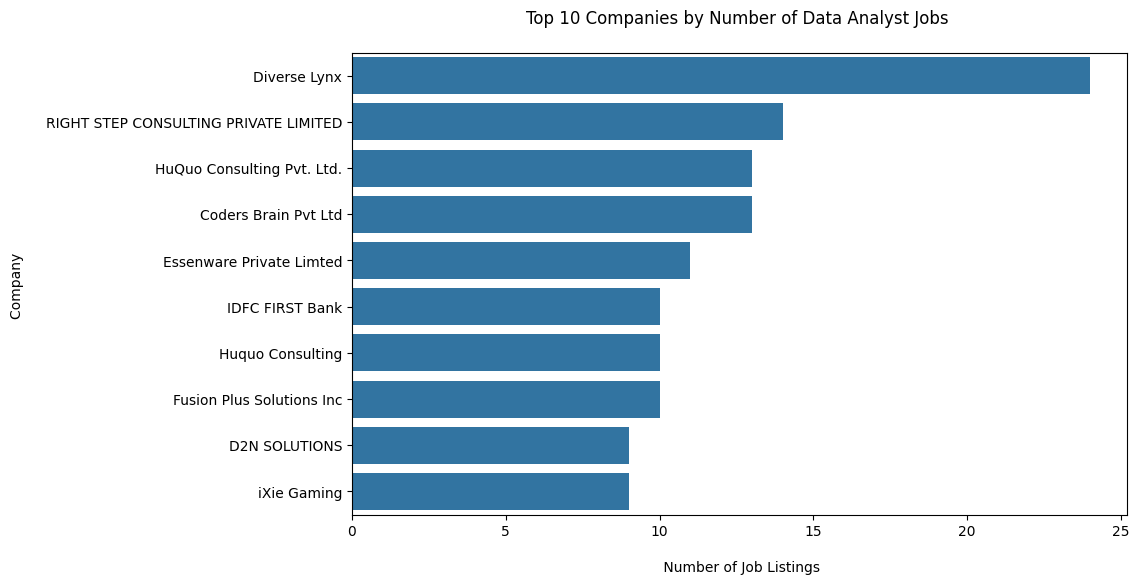

In [ ]:
company_counts = df["company"].value_counts().head(10)

print(company_counts)

plt.figure(figsize=(10, 6))
sns.barplot(
    x=company_counts.values,
    y=company_counts.index
)

plt.title("Top 10 Companies by Number of Data Analyst Jobs \n")
plt.xlabel("\n Number of Job Listings")
plt.ylabel("Company \n")
plt.show()

# 3. Job listings based on Experience Level

The dataset has min exp and max exp, so we can use minimum required experience to categorize jobs.

For example:

0–2 years → Entry Level

3–5 years → Mid Level

6–10 years → Senior Level

10+ years → Very Senior

# Let's Create the categories:

In [ ]:
df["experience_level"] = pd.cut(
    df["min exp"],
    bins=[-1, 2, 5, 10, float("inf")],
    labels=["Entry Level", "Mid Level", "Senior Level", "Very Senior"]
)

df[['min exp','experience_level']].head(10)

,min exp,experience_level
0,4.0,Mid Level
1,5.0,Mid Level
2,7.0,Senior Level
3,2.0,Entry Level
4,5.0,Mid Level
5,4.0,Mid Level
6,5.0,Mid Level
7,2.0,Entry Level
8,6.0,Senior Level
9,5.0,Mid Level


# Let's count the categories

In [ ]:
experience_counts = df["experience_level"].value_counts().sort_index()

print(experience_counts)

experience_level
Entry Level     698
Mid Level       659
Senior Level    161
Very Senior       9
Name: count, dtype: int64


# Let's visualise

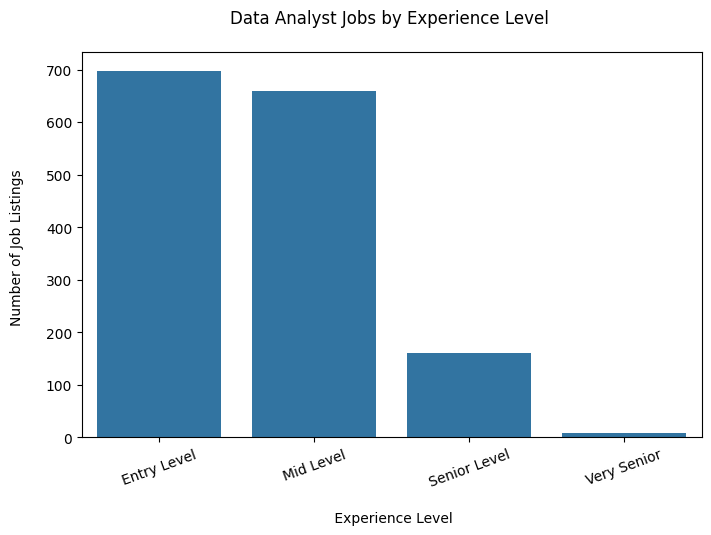

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    x=experience_counts.index,
    y=experience_counts.values
)

plt.title("Data Analyst Jobs by Experience Level \n")
plt.xlabel("\n Experience Level")
plt.ylabel("Number of Job Listings \n")
plt.xticks(rotation=20)
plt.show()

# 4. Distribution of Job Ratings

Now let's analyze the rating column.

First, let's check its distribution:

In [ ]:
print(df["rating"].describe())

count    1124.000000
mean        3.799377
std         0.740237
min         1.000000
25%         3.500000
50%         3.900000
75%         4.200000
max         5.000000
Name: rating, dtype: float64


# Let's create a histogram:

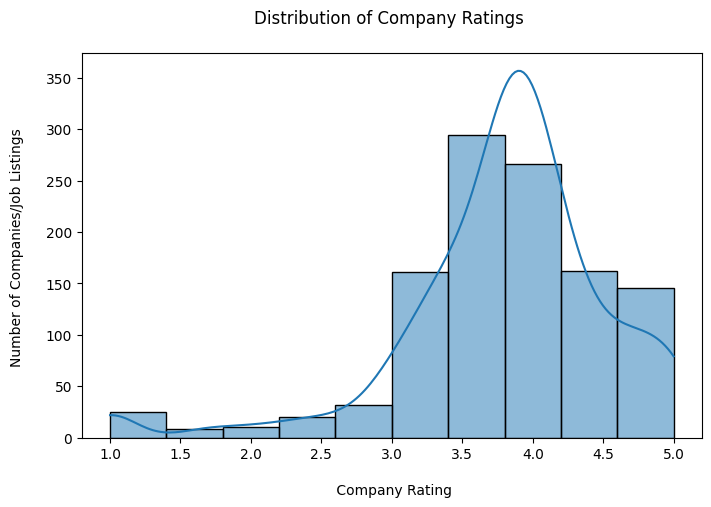

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["rating"].dropna(),
    bins=10,
    kde=True
)

plt.title("Distribution of Company Ratings \n")
plt.xlabel("\n Company Rating")
plt.ylabel("Number of Companies/Job Listings \n")
plt.show()

# The rating statistics are:

Average rating ≈ 3.80

Median rating ≈ 3.90

Minimum = 1.0

Maximum = 5.0

The majority of ratings fall between 3 and 4.5, with ratings from 3–4 being particularly common.

# 5. Distribution of Reviews Count

The reviews count column is highly skewed because some companies have thousands of reviews while many have relatively few.

We can visualize it using a histogram:

In [ ]:
df["reviews count"].describe()

,reviews count
count,1124.000000
mean,959.846975
std,4198.153851
min,1.000000
25%,7.000000
50%,30.000000
75%,242.500000
max,41400.000000


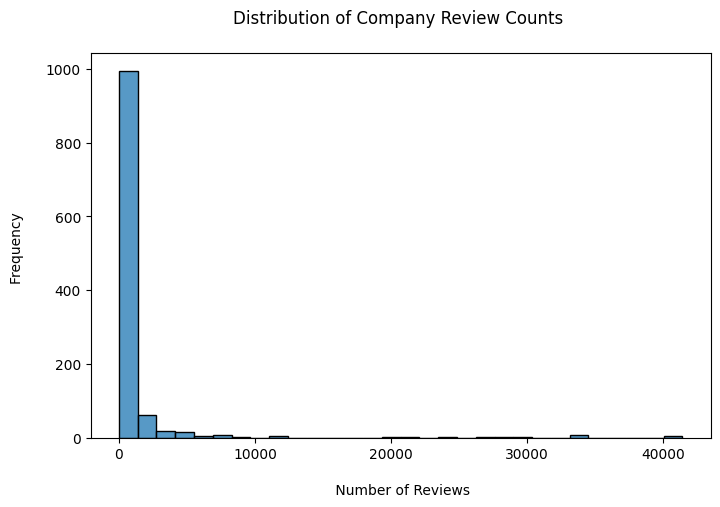

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["reviews count"].dropna(),
    bins=30
)

plt.title("Distribution of Company Review Counts \n")
plt.xlabel("\n Number of Reviews")
plt.ylabel("Frequency \n")
plt.show()

# However, because some companies have extremely large review counts, the graph can become difficult to read.

For example, the dataset contains review counts as high as 41,400.

Therefore, a log scale is useful:

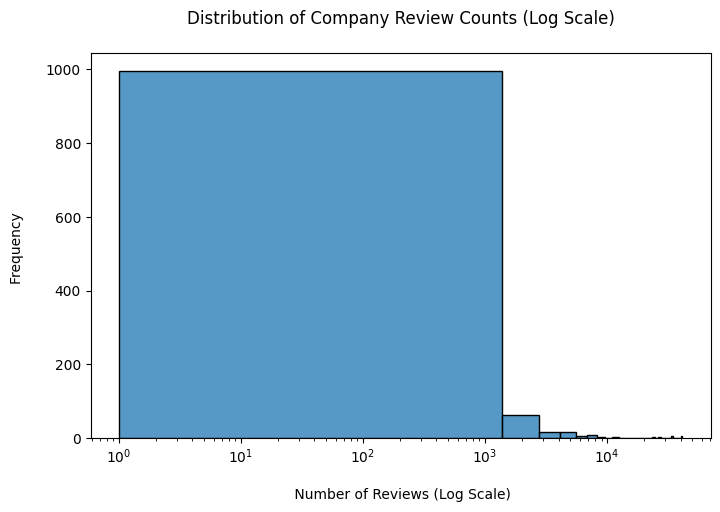

In [ ]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df["reviews count"].dropna(),
    bins=30
)

plt.xscale("log")

plt.title("Distribution of Company Review Counts (Log Scale)\n")
plt.xlabel("\n Number of Reviews (Log Scale)")
plt.ylabel("Frequency \n")
plt.show()

# The review-count statistics show:

Mean   ≈ 959.85

Median = 30

Maximum = 41,400

#This tells us something important:

The mean is much higher than the median, indicating that the review-count distribution is strongly right-skewed. A small number of companies have very large numbers of reviews.

# EDA Findings:
The analysis shows that Bangalore/Bengaluru has the highest number of Data Analyst job listings, followed by Mumbai, Hyderabad, Gurgaon/Gurugram, Pune, and Chennai. Among companies, Diverse Lynx has the highest number of listings in the dataset. In terms of experience, entry-level and mid-level positions account for the majority of job listings, while senior and very senior positions are comparatively fewer. Company ratings are generally concentrated around 3–4.5, with an average rating of approximately 3.8. The review-count distribution is highly right-skewed, with a median of only 30 reviews compared with a much higher mean of approximately 960, indicating that a small number of companies have exceptionally high review counts.

# 3. Statistical Analysis:
○ Conduct hypothesis testing to determine if there's a significant
difference in ratings between jobs posted on 'Naukri' and 'iimjobs'.

○ Perform a correlation analysis between job ratings and reviews
count.


#Part A — Hypothesis Testing
  Our question

We want to know:

Do jobs posted on Naukri and iimjobs have significantly different company ratings?

We have two independent groups:

Naukri

   ↓

Ratings of jobs posted on Naukri


iimjobs

   ↓

Ratings of jobs posted on iimjobs

Because we are comparing the means of two independent groups, we can use an independent two-sample t-test.


#Step 1: Separate the two groups

In [ ]:
naukri = df[df["postedIn"] == "Naukri"]["rating"].dropna()

iimjobs = df[df["postedIn"] == "iimjobs"]["rating"].dropna()



# Let's check their basic statistics

In [ ]:
print("Naukri:")
print(naukri.describe())

print("\n iimjobs:")
print(iimjobs.describe())

Naukri:
count    853.000000
mean       3.817819
std        0.720483
min        1.000000
25%        3.500000
50%        3.900000
75%        4.200000
max        5.000000
Name: rating, dtype: float64

 iimjobs:
count    88.000000
mean      3.836364
std       0.631761
min       1.000000
25%       3.800000
50%       3.850000
75%       4.100000
max       5.000000
Name: rating, dtype: float64


# Step 3: Let's Create hypotheses

We have two hypotheses.

Null hypothesis — H₀

There is no significant difference in the average ratings between Naukri and iimjobs.

In mathematical terms:

H₀ : μNaukri = μiimjobs

Alternative hypothesis — H₁

There is a significant difference in the average ratings between Naukri and iimjobs.

H₁ : μNaukri ≠ μiimjobs

#We'll use:

Significance level (α) = 0.05

# Step 4: Let's Perform the t-test

In [ ]:
from scipy.stats import ttest_ind

t_stat, p_value = ttest_ind(
    naukri,
    iimjobs,
    equal_var=False
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

T-statistic: -0.25855662727012513
P-value: 0.7964531516950539


# Step 5: Interpret the p-value

our rule:

If p-value < 0.05
        ↓
Reject H₀
        ↓
Significant difference

If p-value >= 0.05
        ↓
Fail to reject H₀
        ↓
No statistically significant difference

Our p-value is:

0.796

And:

0.796 > 0.05

Therefore:

We fail to reject the null hypothesis.

#Conclusion:

There is no statistically significant difference in the average company ratings between jobs posted on Naukri and iimjobs in this dataset.

Even though the means are slightly different:

Naukri  = 3.818

iimjobs = 3.836

the difference is not statistically significant.

# Part B — Correlation Analysis

We want to know:

Is there a relationship between company ratings and the number of reviews?

For example, perhaps companies with more reviews have higher ratings.

We can investigate this using Pearson correlation.

# Let's check the correlation

In [ ]:
correlation = df[["rating", "reviews count"]].corr()

print(correlation)

                rating  reviews count
rating         1.00000        0.01881
reviews count  0.01881        1.00000


# What does 0.0188 mean?

The Pearson correlation coefficient ranges from:

-1  ←──────── 0 ────────→ +1

Generally:

Correlation	Meaning

+1	Perfect positive relationship

+0.7	Strong positive

+0.3	Moderate positive

0	No linear relationship

-0.3	Moderate negative

-0.7	Strong negative

-1	Perfect negative

Our result:

r = 0.0188

is very close to 0.

Therefore:

There is almost no linear correlation between company rating and review count in this dataset.

# We can also calculate the p-value

In [ ]:
from scipy.stats import pearsonr

data = df[["rating", "reviews count"]].dropna()

r, p_value = pearsonr(
    data["rating"],
    data["reviews count"]
)

print("Correlation:", r)
print("P-value:", p_value)

Correlation: 0.018810214661345654
P-value: 0.528702853371922


Since:

0.5287 > 0.05

the correlation is not statistically significant.

## We can visualize the correlation

A scatter plot is perfect for this:

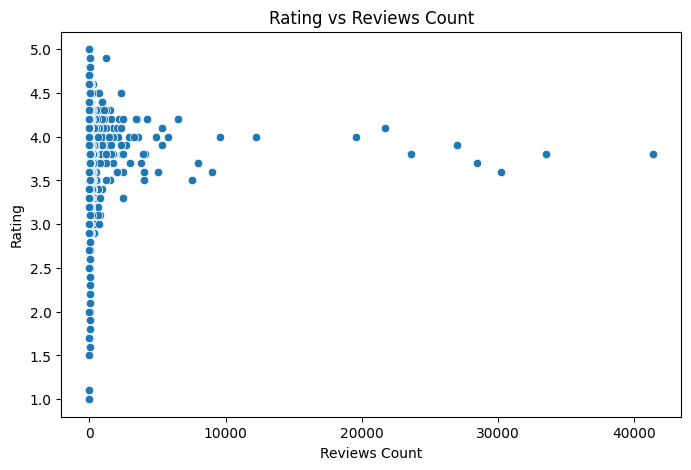

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="reviews count",
    y="rating"
)

plt.title("Rating vs Reviews Count")
plt.xlabel("Reviews Count")
plt.ylabel("Rating")

plt.show()

## Because review counts are highly skewed, we can also use a log scale:

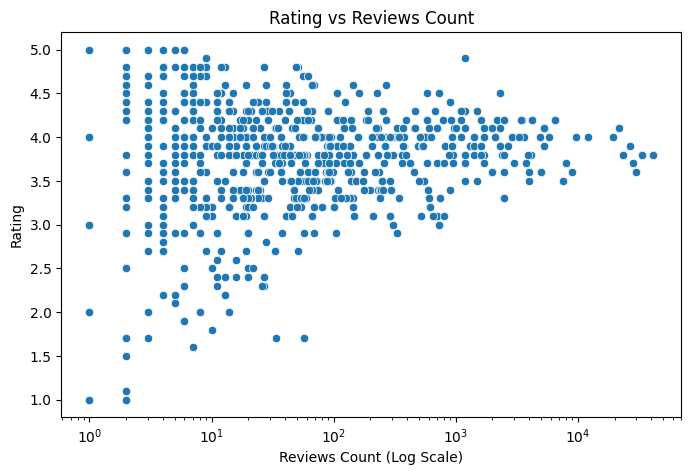

In [ ]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="reviews count",
    y="rating"
)

plt.xscale("log")

plt.title("Rating vs Reviews Count")
plt.xlabel("Reviews Count (Log Scale)")
plt.ylabel("Rating")

plt.show()

#Conclusion

###Hypothesis Testing:
 An independent two-sample Welch's t-test was conducted to determine whether there was a significant difference in ratings between jobs posted on Naukri and iimjobs. The mean rating for Naukri was approximately 3.818, while iimjobs had a mean rating of approximately 3.836. The test produced a t-statistic of -0.259 and a p-value of 0.796. Since the p-value is greater than the significance level of 0.05, we fail to reject the null hypothesis. Therefore, there is no statistically significant difference in ratings between Naukri and iimjobs in this dataset.

###Correlation Analysis:
 Pearson correlation was used to examine the relationship between job ratings and reviews count. The correlation coefficient was approximately 0.019, with a p-value of approximately 0.529. This indicates an extremely weak positive linear relationship that is not statistically significant. Therefore, the number of reviews does not appear to have a meaningful linear relationship with company ratings in this dataset.

# 4. Machine Learning:

Let's Select the features:

We should not use salary or max salary as predictors because they are directly related to the salary information we're trying to predict. Including them could cause data leakage.

##We'll use:

In [ ]:
features = [
    "job_title",
    "company",
    "min exp",
    "max exp",
    "location",
    "jobListed(days ago)",
    "postedIn",
    "rating",
    "reviews count"
]

target = "base salary"

data = df[features + [target]].dropna(subset=[target])

X = data[features]
y = data[target]

In [ ]:
data.head()

,job_title,company,min exp,max exp,location,jobListed(days ago),postedIn,rating,reviews count,base salary
1,Data Analyst - Bangalore,Schneider Electric,5.0,10.0,"Bangalore / Bengaluru, Bangalore Rural",4.0,Naukri,4.2,3500.0,800000.0
18,Data Analyst,Amazon,2.0,4.0,"Delhi/Ncr, Bangalore / Bengaluru",11.0,Naukri,4.1,21700.0,180000.0
26,Specialist - Investments,Jardine Lloyd Thompson India Pvt Ltd.,2.0,5.0,Pune,3.0,Naukri,4.0,558.0,475400.0
28,Veeva process specialists,Tech Mahindra,5.0,10.0,Hyderabad / Secunderabad,3.0,Naukri,3.7,28500.0,700000.0
29,Data Analyst/Sr. Analyst - SAS & Python,FedEx,3.0,8.0,"Mumbai, Bangalore / Bengaluru",17.0,Naukri,4.2,1100.0,1000000.0


# Let's split the data

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Let's handle categorical columns

Our dataset contains both numerical and categorical columns.

Numerical

min exp

max exp

jobListed(days ago)

rating

reviews count

Categorical

job_title

company

location

postedIn

Machine-learning algorithms cannot directly understand values such as:

Bangalore

Mumbai

Hyderabad

###So we use One-Hot Encoding.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

categorical_cols = [
    "job_title",
    "company",
    "location",
    "postedIn"
]

numerical_cols = [
    "min exp",
    "max exp",
    "jobListed(days ago)",
    "rating",
    "reviews count"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("encoder", OneHotEncoder(handle_unknown="ignore"))
            ]),
            categorical_cols
        ),
        (
            "num",
            SimpleImputer(strategy="median"),
            numerical_cols
        )
    ]
)

# Build the Machine Learning model

For this dataset, we can use a Random Forest Regressor.

In [ ]:
from sklearn.ensemble import RandomForestRegressor

model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    max_features="sqrt",
    min_samples_leaf=2,
    n_jobs=-1
)

# Let's create the pipeline

In [ ]:
pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", model)
])


pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['job_title', 'company',
                                                   'location', 'postedIn']),
                                                 ('num',
                                                  SimpleImputer(strategy='median'),
                                                  ['min exp', 'max exp',
                                                   'jobListed(days ago)',
                                                   'rating',
                                                   'reviews count'])])),
                ('model',
                 RandomForestRegressor(max_features='sqrt', min_samples_leaf=2,
                                       n_estimators=300, n_jobs=-1,
                                       random_state=42))])

# Make Predictions

In [ ]:
y_pred = pipeline.predict(X_test)


# Evaluate the model

For regression, three important metrics are:

###1. MAE — Mean Absolute Error

In [ ]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(y_test, y_pred)

print("MAE:", mae)

MAE: 357093.6985676199


### MAE tells us the average absolute difference between actual and predicted salary.

Our model produced approximately:

MAE = ₹357,094

So, roughly speaking, predictions were off by about ₹3.57 lakh on average.

# 2. RMSE — Root Mean Squared Error

In [ ]:
from sklearn.metrics import mean_squared_error

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

RMSE: 449478.03751835594


#Our result was approximately:

RMSE = ₹449,478

RMSE penalizes larger errors more heavily than MAE.

# 3. R² Score

In [ ]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.1718085875350045


#Our result was approximately:

R² = 0.172

That means the model explains roughly 17.2% of the variation in base salary using these features.

# Feature Selection

In [ ]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    pipeline,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="r2"
)

importance = pd.Series(
    result.importances_mean,
    index=features
).sort_values(ascending=False)

print(importance)

company                0.052523
job_title              0.042609
min exp                0.038152
max exp                0.036787
jobListed(days ago)    0.027978
rating                 0.005797
location               0.001920
postedIn               0.000546
reviews count          0.000288
dtype: float64


# What does this tell us?

The strongest features in this model were:

Company

Job title

Minimum experience

Maximum experience

This makes intuitive sense.

# Conclusion:
A Random Forest Regression model was developed to predict the base salary of Data Analyst jobs using job title, company, experience, location, rating, reviews count, posting platform, and listing age. Rows with missing base salary values were excluded from the modeling dataset, resulting in 343 observations. The model achieved an MAE of approximately ₹357,094, an RMSE of approximately ₹449,478, and an R² score of approximately 0.172 on the test data. The relatively low R² indicates that the selected features explain only a limited portion of the variation in base salary.

Feature selection using permutation importance showed that company, job title, minimum experience, and maximum experience were the most influential features for predicting base salary. Rating, location, posting platform, and reviews count had comparatively lower importance in this model.
